# Hotel booking cancellation risk

A hotel receives a new booking and has to decide right away whether to treat it as firm. This notebook builds a model that estimates the probability of cancellation using only what is known when the booking is created.

The notebook covers data cleaning, exploratory analysis, leakage checks, model selection and the choice of a decision threshold. The final model is trained by `train.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

BAR_COLOR = "#2a6f97"
REFERENCE_COLOR = "#6b7280"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e7eb",
    "grid.linewidth": 0.8,
})
pd.set_option("display.max_columns", 40)

## 1. Load the data

The data is the Hotel Booking Demand dataset published by Antonio, Almeida and Nunes (*Data in Brief*, 2019). It describes bookings for one city hotel and one resort hotel in Portugal, with arrivals between July 2015 and August 2017.

In [2]:
df_raw = pd.read_csv("data/hotel_bookings.csv", dtype={"agent": str, "company": str})
df_raw["arrival_date"] = pd.to_datetime(
    df_raw["arrival_date_year"].astype(str)
    + "-" + df_raw["arrival_date_month"]
    + "-" + df_raw["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
print(df_raw.shape)
df_raw.head()

(119390, 33)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01


In [3]:
df_raw.dtypes

hotel                                        str
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                           str
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                         str
country                                      str
market_segment                               str
distribution_channel                         str
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                           str
assigned_room_type  

In [4]:
df_raw.describe().T[["min", "mean", "50%", "max"]]

,min,mean,50%,max
is_canceled,0.0,0.370416,0.0,1.0
lead_time,0.0,104.011416,69.0,737.0
arrival_date_year,2015.0,2016.156554,2016.0,2017.0
arrival_date_week_number,1.0,27.165173,28.0,53.0
arrival_date_day_of_month,1.0,15.798241,16.0,31.0
stays_in_weekend_nights,0.0,0.927599,1.0,19.0
stays_in_week_nights,0.0,2.500302,2.0,50.0
adults,0.0,1.856403,2.0,55.0
children,0.0,0.10389,0.0,10.0
babies,0.0,0.007949,0.0,10.0


## 2. Missing values and invalid records

In [5]:
missing = df_raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["share"] = (missing["missing"] / len(df_raw)).round(4)
missing

,missing,share
children,4,0.0000
country,488,0.0041
agent,16340,0.1369
company,112593,0.9431


In [6]:
guests = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
nights = df_raw["stays_in_weekend_nights"] + df_raw["stays_in_week_nights"]

pd.Series({
    "no guests": (guests == 0).sum(),
    "no nights": (nights == 0).sum(),
    "negative adr": (df_raw["adr"] < 0).sum(),
    "zero adr": (df_raw["adr"] == 0).sum(),
    "adr above 1000": (df_raw["adr"] > 1000).sum(),
    "exact duplicates": df_raw.duplicated().sum(),
}).to_frame("rows")

,rows
no guests,180
no nights,715
negative adr,1
zero adr,1959
adr above 1000,1
exact duplicates,31994


Cleaning decisions:

- `agent` and `company` are identifiers, so they stay as strings. A missing value means the booking did not come through an agent or a company, so it becomes `none`.
- `children` has 4 missing values, which become 0. Missing `country` becomes `unknown`.
- Bookings with no guests are invalid and are removed. So are the negative price and the single price of 5400, which is more than ten times the next highest value.
- Zero-night and zero-price records are kept. Day use and complimentary stays are real, and `market_segment` records the complimentary ones.
- Exact duplicates are kept. The data has no booking id, and most duplicates look like blocks of rooms booked together. Section 5 uses a time-based split, so duplicates cannot fall on both sides of it, and section 8 reports the score with duplicates removed.

In [7]:
df = df_raw[(guests > 0) & df_raw["adr"].between(0, 1000)].copy()
df["children"] = df["children"].fillna(0).astype(int)
df["agent"] = df["agent"].fillna("none")
df["company"] = df["company"].fillna("none")
df["country"] = df["country"].fillna("unknown")
print(len(df_raw) - len(df), "rows removed,", len(df), "rows left")

182 rows removed, 119208 rows left


## 3. Target

cancellation rate: 0.371


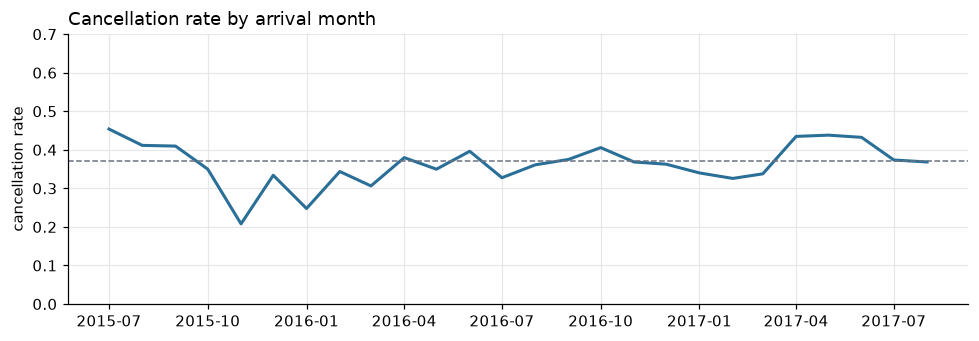

In [8]:
print(f"cancellation rate: {df['is_canceled'].mean():.3f}")

monthly = df.set_index("arrival_date").resample("MS")["is_canceled"].mean()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(monthly.index, monthly.values, color=BAR_COLOR, linewidth=2)
ax.axhline(df["is_canceled"].mean(), color=REFERENCE_COLOR, linewidth=1, linestyle="--")
ax.set_ylim(0, 0.7)
ax.set_ylabel("cancellation rate")
ax.set_title("Cancellation rate by arrival month", loc="left")
plt.tight_layout()
plt.show()

The classes are reasonably balanced, so no resampling is needed. The rate moves from month to month, which is one reason to evaluate on later arrivals than the ones used for training.

## 4. Feature analysis

### 4.1 Numerical features

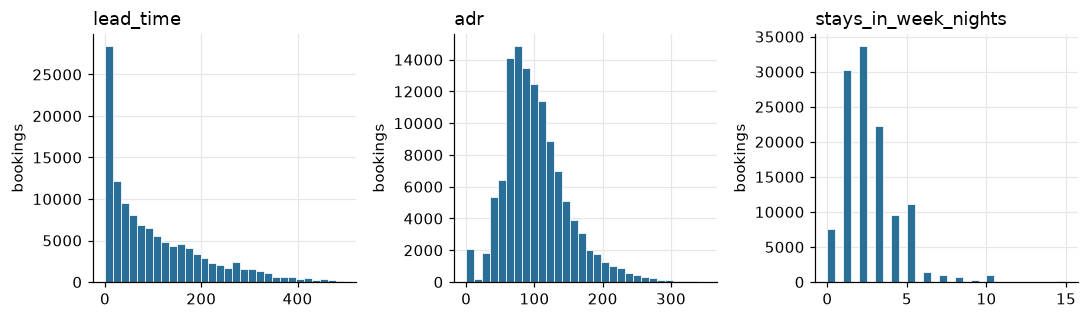

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
columns = ["lead_time", "adr", "stays_in_week_nights"]
limits = [500, 350, 15]

for ax, column, limit in zip(axes, columns, limits):
    values = df.loc[df[column] <= limit, column]
    ax.hist(values, bins=30, color=BAR_COLOR, edgecolor="white", linewidth=0.5)
    ax.set_title(column, loc="left")
    ax.set_ylabel("bookings")

plt.tight_layout()
plt.show()

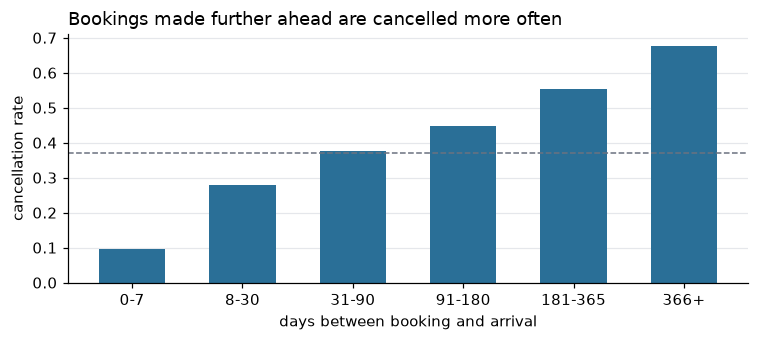

,mean,size
lead_time,,
0-7,0.096002,19635
8-30,0.278860,18945
31-90,0.377269,29528
91-180,0.447350,26420
181-365,0.554591,21533
366+,0.676517,3147


In [10]:
buckets = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
                 labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])
by_lead_time = df.groupby(buckets, observed=True)["is_canceled"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_lead_time.index.astype(str), by_lead_time["mean"], color=BAR_COLOR, width=0.6)
ax.axhline(df["is_canceled"].mean(), color=REFERENCE_COLOR, linewidth=1, linestyle="--")
ax.set_xlabel("days between booking and arrival")
ax.set_ylabel("cancellation rate")
ax.set_title("Bookings made further ahead are cancelled more often", loc="left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
by_lead_time

### 4.2 Categorical features

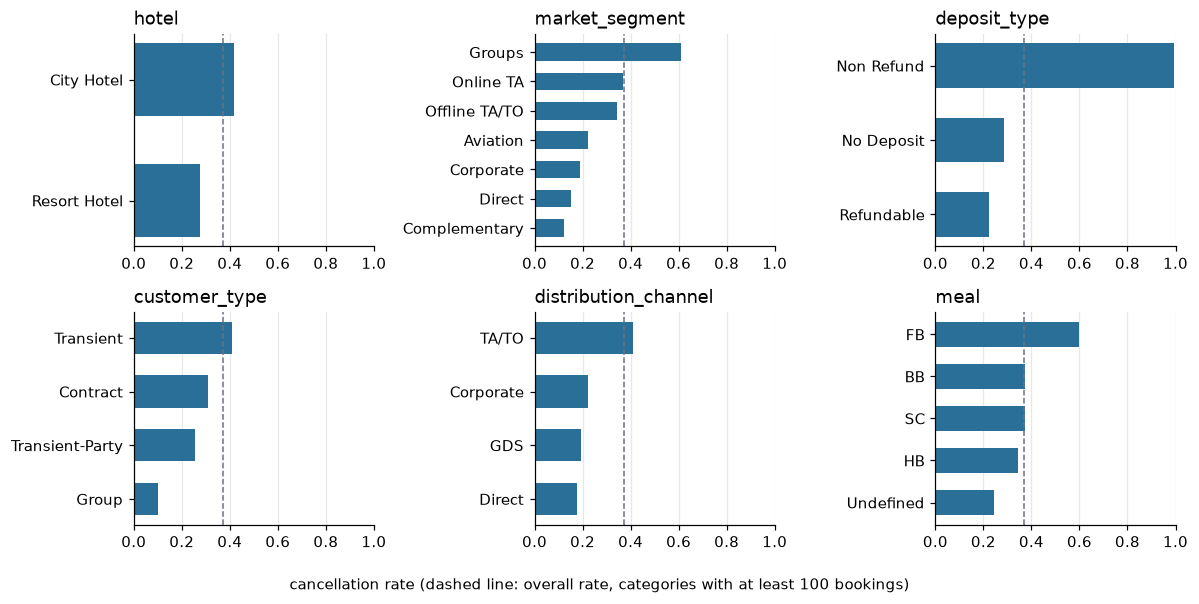

In [11]:
def plot_rate(ax, column):
    rates = (df.groupby(column)["is_canceled"].agg(["mean", "size"])
             .query("size >= 100").sort_values("mean"))
    ax.barh(rates.index.astype(str), rates["mean"], color=BAR_COLOR, height=0.6)
    ax.axvline(df["is_canceled"].mean(), color=REFERENCE_COLOR, linewidth=1, linestyle="--")
    ax.set_xlim(0, 1)
    ax.set_title(column, loc="left")
    ax.grid(axis="y", visible=False)


columns = ["hotel", "market_segment", "deposit_type", "customer_type", "distribution_channel", "meal"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))

for ax, column in zip(axes.flat, columns):
    plot_rate(ax, column)

fig.supxlabel("cancellation rate (dashed line: overall rate, categories with at least 100 bookings)", fontsize=10)
plt.tight_layout()
plt.show()

### 4.3 Which features are available at booking time?

The model is meant to score a booking when it is created. Some columns are only filled in or changed later, and they would make the offline score look better than the service can be in production.

In [12]:
def rates_for(mask, name):
    group = df[mask]
    return {"group": name, "bookings": len(group), "cancellation rate": round(group["is_canceled"].mean(), 3)}


pd.DataFrame([
    rates_for(df["reservation_status"] == "Check-Out", "reservation_status = Check-Out"),
    rates_for(df["reservation_status"] != "Check-Out", "reservation_status != Check-Out"),
    rates_for(df["reserved_room_type"] != df["assigned_room_type"], "assigned room differs from reserved"),
    rates_for(df["reserved_room_type"] == df["assigned_room_type"], "assigned room same as reserved"),
    rates_for(df["required_car_parking_spaces"] > 0, "parking space required"),
    rates_for(df["required_car_parking_spaces"] == 0, "no parking space required"),
    rates_for(df["booking_changes"] > 0, "booking changed at least once"),
    rates_for(df["booking_changes"] == 0, "booking never changed"),
    rates_for(df["total_of_special_requests"] > 0, "at least one special request"),
    rates_for(df["total_of_special_requests"] == 0, "no special requests"),
    rates_for(df["country"] == "PRT", "country = PRT"),
    rates_for(df["country"].isin(["GBR", "FRA", "DEU", "ESP"]), "country in GBR, FRA, DEU, ESP"),
    rates_for(df["deposit_type"] == "Non Refund", "deposit_type = Non Refund"),
    rates_for(df["deposit_type"] == "No Deposit", "deposit_type = No Deposit"),
])

,group,bookings,cancellation rate
0,reservation_status = Check-Out,75010,0.000
1,reservation_status != Check-Out,44198,1.000
2,assigned room differs from reserved,14795,0.054
3,assigned room same as reserved,104413,0.416
4,parking space required,7409,0.000
5,no parking space required,111799,0.395
6,booking changed at least once,17976,0.157
7,booking never changed,101232,0.409
8,at least one special request,49009,0.218
9,no special requests,70199,0.478


Decisions:

| Column | Decision | Reason |
|---|---|---|
| `reservation_status`, `reservation_status_date` | removed | They record the outcome itself. |
| `assigned_room_type` | removed | The room is assigned close to arrival, so a cancelled booking usually keeps the reserved type. |
| `booking_changes` | removed | The counter grows after the booking is created. |
| `required_car_parking_spaces` | removed | No booking with a parking space was ever cancelled, which suggests the value is mostly recorded on arrival. |
| `total_of_special_requests` | removed | Requests can be added after the booking is created. |
| `country` | removed | Portuguese bookings are cancelled about three times as often as those from nearby countries. That pattern fits a default value that is corrected at check-in. The data cannot prove it, so this is a conservative choice. |
| `arrival_date_year` | removed | A future booking never has a year seen in training. |
| `arrival_date_day_of_month` | removed | It has no plausible seasonal meaning beyond month and week. |
| `deposit_type` | kept | It is known at booking time. The 99% rate for `Non Refund` is unusual, so the final score is also reported for `No Deposit` bookings only. |

Section 7 measures how much each removed column would have inflated the score.

## 5. Features and time-based split

In production the model is trained on past bookings and scores future ones, so the split follows arrival date.

| Part | Arrivals |
|---|---|
| train | before October 2016 |
| validation | October 2016 to March 2017 |
| test | from April 2017 |

In [13]:
NUMERICAL = [
    "lead_time", "arrival_date_week_number", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "days_in_waiting_list", "adr",
]
CATEGORICAL = [
    "hotel", "arrival_date_month", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type", "agent", "company", "customer_type",
]
FEATURES = NUMERICAL + CATEGORICAL

df_train = df[df["arrival_date"] < "2016-10-01"]
df_val = df[(df["arrival_date"] >= "2016-10-01") & (df["arrival_date"] < "2017-04-01")]
df_test = df[df["arrival_date"] >= "2017-04-01"]

for name, part in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    print(f"{name:<11}{len(part):>7} rows, cancellation rate {part['is_canceled'].mean():.3f}")

train        64113 rows, cancellation rate 0.358
validation   27265 rows, cancellation rate 0.360
test         27830 rows, cancellation rate 0.412


### Feature importance on the training part

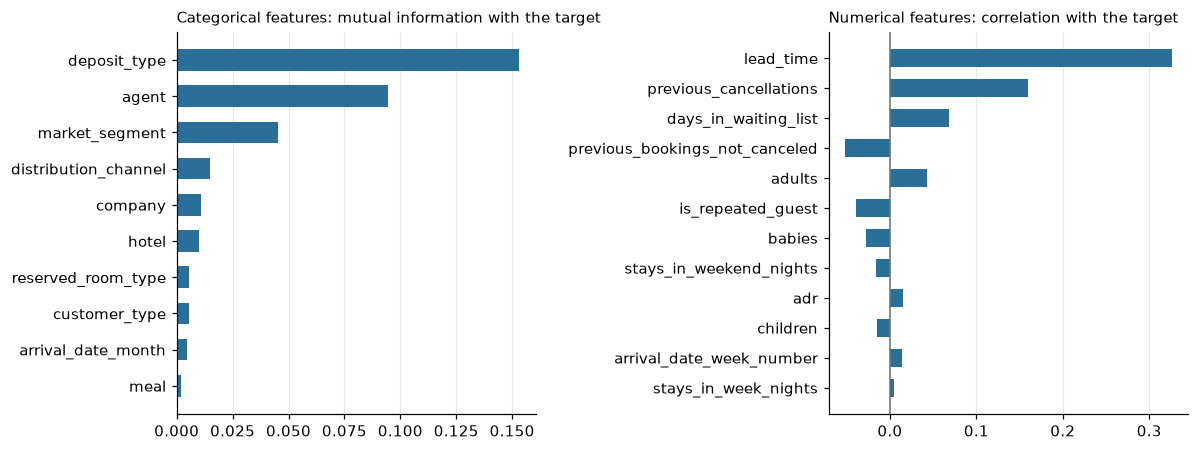

In [14]:
importance = (df_train[CATEGORICAL]
              .apply(lambda column: mutual_info_score(column, df_train["is_canceled"]))
              .sort_values())

correlation = (df_train[NUMERICAL]
               .corrwith(df_train["is_canceled"])
               .sort_values(key=np.abs))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].barh(importance.index, importance.values, color=BAR_COLOR, height=0.6)
axes[0].set_title("Categorical features: mutual information with the target", loc="left", fontsize=10)
axes[0].grid(axis="y", visible=False)

axes[1].barh(correlation.index, correlation.values, color=BAR_COLOR, height=0.6)
axes[1].axvline(0, color=REFERENCE_COLOR, linewidth=1)
axes[1].set_title("Numerical features: correlation with the target", loc="left", fontsize=10)
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

## 6. Model selection

Each model family is tuned on the validation part with ROC AUC, which measures how well bookings are ranked by risk and does not depend on a threshold.

In [15]:
def records(frame, features=FEATURES):
    return frame[features].to_dict(orient="records")


y_train = df_train["is_canceled"].values
y_val = df_val["is_canceled"].values
y_test = df_test["is_canceled"].values

train_records = records(df_train)
val_records = records(df_val)


def validate(*steps):
    pipeline = make_pipeline(DictVectorizer(), *steps)
    pipeline.fit(train_records, y_train)
    return roc_auc_score(y_val, pipeline.predict_proba(val_records)[:, 1])

### Logistic regression

In [16]:
logistic_scores = []

for C in [0.001, 0.01, 0.1, 1, 10]:
    auc = validate(
        StandardScaler(with_mean=False),
        LogisticRegression(C=C, solver="liblinear", max_iter=1000),
    )
    logistic_scores.append({"C": C, "auc": round(auc, 4)})

logistic_scores = pd.DataFrame(logistic_scores)
logistic_scores

,C,auc
0,0.001,0.8016
1,0.010,0.7999
2,0.100,0.7964
3,1.000,0.7953
4,10.000,0.7953


### Decision tree

In [17]:
tree_scores = []

for max_depth in [4, 8, 12, 16]:
    for min_samples_leaf in [20, 100, 500]:
        auc = validate(DecisionTreeClassifier(
            max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=1,
        ))
        tree_scores.append({"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "auc": round(auc, 4)})

tree_scores = pd.DataFrame(tree_scores)
tree_scores.pivot(index="max_depth", columns="min_samples_leaf", values="auc")

min_samples_leaf,20,100,500
max_depth,,,
4,0.7768,0.7767,0.7818
8,0.8119,0.8131,0.8103
12,0.7833,0.7841,0.8058
16,0.7848,0.7778,0.8061


### Random forest

In [18]:
forest_scores = []

for max_depth in [10, 20, None]:
    for min_samples_leaf in [1, 5, 20]:
        auc = validate(RandomForestClassifier(
            n_estimators=200, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
            random_state=1, n_jobs=-1,
        ))
        forest_scores.append({"max_depth": str(max_depth), "min_samples_leaf": min_samples_leaf, "auc": round(auc, 4)})

forest_scores = pd.DataFrame(forest_scores)
forest_scores.pivot(index="max_depth", columns="min_samples_leaf", values="auc")

min_samples_leaf,1,5,20
max_depth,,,
10,0.8176,0.8152,0.8163
20,0.8216,0.8206,0.8169
None,0.7971,0.8217,0.8181


### XGBoost

In [19]:
xgb_scores = []

for learning_rate in [0.03, 0.1, 0.3]:
    for max_depth in [3, 4, 6, 8]:
        for min_child_weight in [1, 10]:
            for n_estimators in [200, 500]:
                auc = validate(XGBClassifier(
                    learning_rate=learning_rate, max_depth=max_depth,
                    min_child_weight=min_child_weight, n_estimators=n_estimators,
                    random_state=1, n_jobs=-1,
                ))
                xgb_scores.append({
                    "learning_rate": learning_rate, "max_depth": max_depth,
                    "min_child_weight": min_child_weight, "n_estimators": n_estimators,
                    "auc": round(auc, 4),
                })

xgb_scores = pd.DataFrame(xgb_scores).sort_values("auc", ascending=False)
xgb_scores.head(8)

,learning_rate,max_depth,min_child_weight,n_estimators,auc
36,0.30,4,1,200,0.8234
22,0.10,4,10,200,0.8228
20,0.10,4,1,200,0.8228
7,0.03,4,10,500,0.8218
13,0.03,8,1,500,0.8218
9,0.03,6,1,500,0.8218
12,0.03,8,1,200,0.8217
18,0.10,3,10,200,0.8215


In [20]:
summary = pd.DataFrame([
    {"model": "logistic regression", "validation auc": logistic_scores["auc"].max()},
    {"model": "decision tree", "validation auc": tree_scores["auc"].max()},
    {"model": "random forest", "validation auc": forest_scores["auc"].max()},
    {"model": "xgboost", "validation auc": xgb_scores["auc"].max()},
]).sort_values("validation auc", ascending=False)
summary

,model,validation auc
3,xgboost,0.8234
2,random forest,0.8217
1,decision tree,0.8131
0,logistic regression,0.8016


In [21]:
best = xgb_scores.iloc[0]
XGB_PARAMS = {
    "learning_rate": float(best["learning_rate"]),
    "max_depth": int(best["max_depth"]),
    "min_child_weight": int(best["min_child_weight"]),
    "n_estimators": int(best["n_estimators"]),
    "random_state": 1,
    "n_jobs": -1,
}
XGB_PARAMS

{'learning_rate': 0.3,
 'max_depth': 4,
 'min_child_weight': 1,
 'n_estimators': 200,
 'random_state': 1,
 'n_jobs': -1}

XGBoost has the best validation AUC (0.8234), just ahead of the random forest (0.8217). The decision tree reaches 0.8131 and logistic regression 0.8016. Logistic regression keeps improving slightly with stronger regularization, but the gap to the tree ensembles is too large for more tuning to close. XGBoost is selected with `learning_rate=0.3`, `max_depth=4`, `min_child_weight=1` and `n_estimators=200`.

## 7. How much would leakage have inflated the score?

The tuned XGBoost is retrained with each removed column added back.

In [22]:
def validate_features(features):
    pipeline = make_pipeline(DictVectorizer(), XGBClassifier(**XGB_PARAMS))
    pipeline.fit(records(df_train, features), y_train)
    return roc_auc_score(y_val, pipeline.predict_proba(records(df_val, features))[:, 1])


leak_scores = [{"features": "selected features", "auc": validate_features(FEATURES)}]

for column in ["assigned_room_type", "booking_changes", "required_car_parking_spaces",
               "total_of_special_requests", "country"]:
    leak_scores.append({"features": f"+ {column}", "auc": validate_features(FEATURES + [column])})

leak_scores.append({
    "features": "+ all five",
    "auc": validate_features(FEATURES + ["assigned_room_type", "booking_changes",
                                         "required_car_parking_spaces",
                                         "total_of_special_requests", "country"]),
})
leak_scores.append({
    "features": "- deposit_type",
    "auc": validate_features([f for f in FEATURES if f != "deposit_type"]),
})

pd.DataFrame(leak_scores).round(4)

,features,auc
0,selected features,0.8234
1,+ assigned_room_type,0.8342
2,+ booking_changes,0.8264
3,+ required_car_parking_spaces,0.8328
4,+ total_of_special_requests,0.8448
5,+ country,0.8596
6,+ all five,0.8985
7,- deposit_type,0.8103


Adding the five removed columns back would raise validation AUC from 0.8234 to 0.8985. That higher score would not be available when the booking is created, so it is not used. Removing `deposit_type` only lowers AUC to 0.8103, so the model does not depend on that column alone.

## 8. Final evaluation

The final model is trained on train and validation together and scored once on the test part.

In [23]:
df_full_train = pd.concat([df_train, df_val])

final_model = make_pipeline(DictVectorizer(), XGBClassifier(**XGB_PARAMS))
final_model.fit(records(df_full_train), df_full_train["is_canceled"].values)

test_proba = final_model.predict_proba(records(df_test))[:, 1]

no_deposit = (df_test["deposit_type"] == "No Deposit").values
unique_rows = (~df_test.drop(columns="arrival_date").duplicated()).values

pd.Series({
    "test auc": roc_auc_score(y_test, test_proba),
    "test auc, No Deposit bookings only": roc_auc_score(y_test[no_deposit], test_proba[no_deposit]),
    "test auc, duplicates removed": roc_auc_score(y_test[unique_rows], test_proba[unique_rows]),
}).round(4)

test auc                              0.8053
test auc, No Deposit bookings only    0.7424
test auc, duplicates removed          0.7532
dtype: float64

The test AUC is 0.8053, which is lower than the validation AUC of 0.8234. The test period also has a higher cancellation rate (0.412 against 0.360), so some drop is expected for a model scored on later arrivals. The score is 0.7424 for `No Deposit` bookings, which excludes the almost deterministic `Non Refund` group, and 0.7532 with duplicates removed. These two numbers are the fairest view of how well the model ranks ordinary bookings.

## 9. Decision threshold

The service flags risky bookings so staff can ask for a prepayment. Asking a reliable guest to prepay can lose the booking, so precision matters more than recall. The threshold is the lowest one that reaches a precision of 0.75 on the validation part.

In [24]:
validation_model = make_pipeline(DictVectorizer(), XGBClassifier(**XGB_PARAMS))
validation_model.fit(train_records, y_train)
val_proba = validation_model.predict_proba(val_records)[:, 1]

rows = []

for threshold in np.arange(0.3, 0.91, 0.05):
    predicted = val_proba >= threshold
    rows.append({
        "threshold": round(float(threshold), 2),
        "precision": round(precision_score(y_val, predicted, zero_division=0), 3),
        "recall": round(recall_score(y_val, predicted), 3),
        "flagged share": round(predicted.mean(), 3),
    })

thresholds = pd.DataFrame(rows)
thresholds

,threshold,precision,recall,flagged share
0,0.30,0.661,0.671,0.365
1,0.35,0.696,0.598,0.309
2,0.40,0.741,0.527,0.256
3,0.45,0.809,0.458,0.204
4,0.50,0.852,0.413,0.174
5,0.55,0.886,0.382,0.155
6,0.60,0.930,0.352,0.136
7,0.65,0.959,0.330,0.124
8,0.70,0.982,0.320,0.117
9,0.75,0.990,0.313,0.114


In [25]:
THRESHOLD = thresholds.loc[thresholds["precision"] >= 0.75, "threshold"].min()
test_predicted = test_proba >= THRESHOLD

pd.Series({
    "threshold": THRESHOLD,
    "test precision": precision_score(y_test, test_predicted),
    "test recall": recall_score(y_test, test_predicted),
    "test flagged share": test_predicted.mean(),
}).round(3)

threshold             0.450
test precision        0.681
test recall           0.650
test flagged share    0.393
dtype: float64

The target was not met on the test part. The threshold of 0.45 gives a precision of 0.681 and a recall of 0.650, and it flags 39.3% of bookings compared with 20.4% on validation. The threshold was chosen on validation only and was not changed after looking at the test part. Before real use it should be checked on recent bookings and adjusted to the hotel's current cancellation level.

## 10. What drives the final model

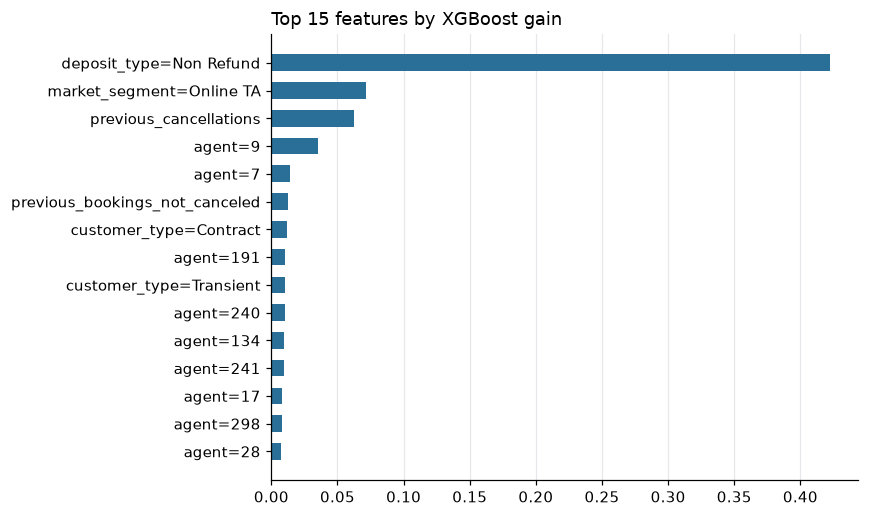

In [26]:
vectorizer = final_model.named_steps["dictvectorizer"]
booster = final_model.named_steps["xgbclassifier"]

gain = (pd.Series(booster.feature_importances_, index=vectorizer.get_feature_names_out())
        .sort_values().tail(15))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(gain.index, gain.values, color=BAR_COLOR, height=0.6)
ax.set_title("Top 15 features by XGBoost gain", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

`deposit_type=Non Refund` dominates the gain, followed by the online travel agency segment and the guest's previous cancellations. Several individual agents also matter, which means a new agent is scored without that information: `DictVectorizer` ignores categories it has not seen.